<a href="https://colab.research.google.com/github/ayeshahabib01/A04-clustering/blob/main/notebook_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ayesha Habib

**Date:** 10/12/26

In [ ]:
# Your Phase 1 solution to the problem goes here.


Q1

In [1]:
# 1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

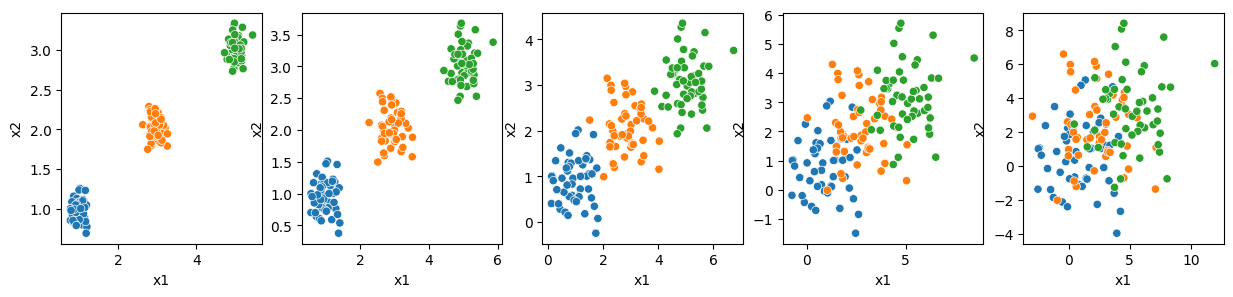

In [4]:
# 2

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, df in zip(axes, [df0_125, df0_25, df0_5, df1_0, df2_0]):
  sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax, legend=False)
plt.show()

# the visual distinctness of the clusters gets less and less as we increase noise levels.
# This is clearly seen by how tight the clusters are in the far left plot and in constrast, the cloud of points in the far right plot



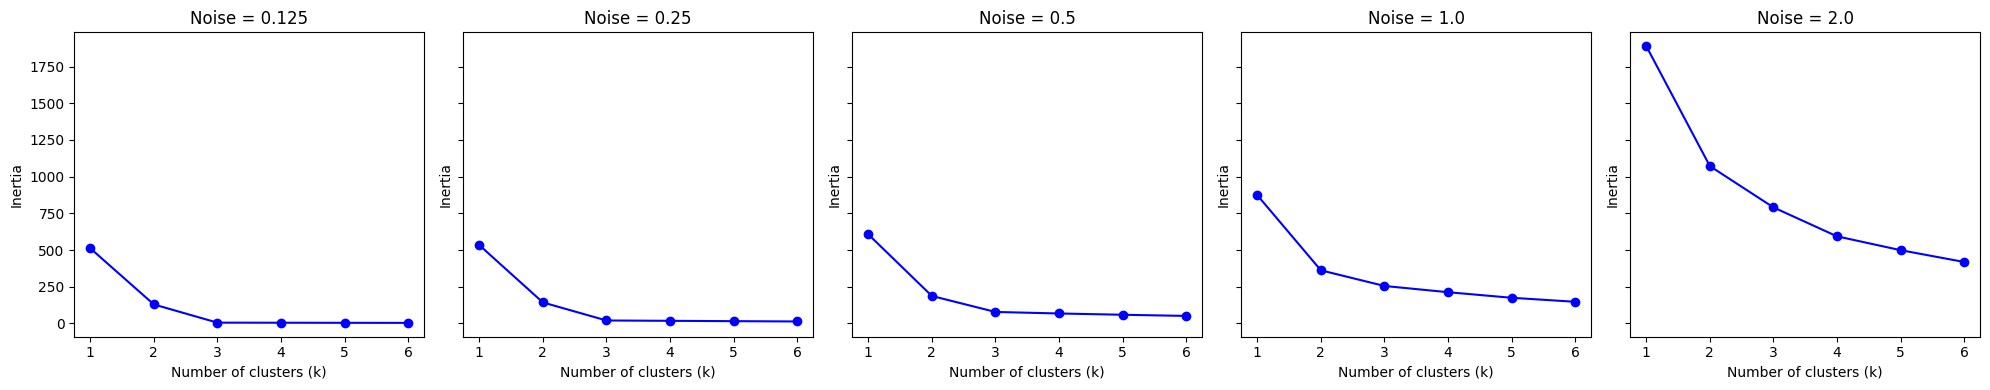

In [5]:
# 3

# scree plots for each dataset

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]
k_range = range(1, 7)

# figure with 1 row and 5 columns (one for each dataset)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for ax, df, noise in zip(axes, datasets, noises):
    inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(df[['x1', 'x2']]).inertia_ for k in k_range]
    ax.plot(k_range, inertias, marker='o', color='b')
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('Number of clusters (k)')
    ax.set_ylabel('Inertia')

plt.tight_layout()
plt.show()

# the higher the level of noise, the less dramatic the "elbow" is; we can see this as you go to lower levels of noise where the "elbow" is sharper
# additionally, the higher noise levels start at higher Inertia values on the y-axis

In [6]:
# 4

# intution of the elbow:

# the elbow represents how spread out the data points are within their assigned clusters.
# as k increases, the clusters get smaller and tighter, which decreases how spread out they are.
# for example, a dataset with a sharp elbow indicates that the data points are very isolated among the k clusters like in the blue line for noise = 0.125.
# the overarching connection between our scree plots and the elbow is that it represents diminishing returns.
# for example, once you reach the point where you have too many k clusters, it becomes inefficient and adds unnecessary complexity.

Q2

In [8]:
# 1

# load data

import pandas as pd
data = pd.read_csv('SIPRI Military Expenditure Database.csv')

# filter the rows to select only the year 2020
data1 = data[data['Year'] == 2020]

# drop all rows with missing values
data2 = data1.dropna()

data2.head(100)

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
3670,3670,2020,Mozambique,288.258946,0.020206,0.061866,9.222811
3704,3704,2020,Myanmar,3208.280460,0.029546,0.138143,45.914890
3738,3738,2020,Namibia,368.224739,0.032271,0.084131,144.913317
3772,3772,2020,Nepal,435.462088,0.013996,0.048053,14.945330


In [9]:
print(len(data2))

148


In [10]:
# looking at the .info() output, the dataset seems to be in good shape to proceed (no missing values and correct data types).
# however, upon looking at the data2 output, we see that the index column is still carrying over from before filtering/dropping nulls.
# this is why I would use code to reset the index
# otherwise, I believe no other further cleaning of the variables is required at this point.

data2.info()
data2 = data2.reset_index(drop=True)

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


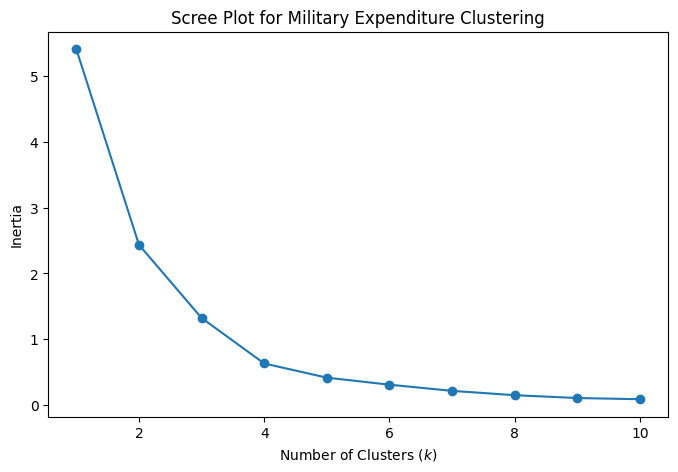

In [11]:
# 2

# max-min normalize Spending (2020 USD) and Spending per Capita

from sklearn.preprocessing import MinMaxScaler

# initialize scaler
scaler = MinMaxScaler()

# select the two features
features = ['Spending (2020 USD)', 'Spending per Capita']

# apply Min-Max scaling and store as new columns
data2[['Spending_Scaled', 'PerCapita_Scaled']] = scaler.fit_transform(data2[features])

# determining optimal number of clusters with scree plot

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data2[['Spending_Scaled', 'PerCapita_Scaled']])
    inertia.append(kmeans.inertia_)

# Plot the scree plot
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-')
plt.xlabel('Number of Clusters ($k$)')
plt.ylabel('Inertia')
plt.title('Scree Plot for Military Expenditure Clustering')
plt.show()

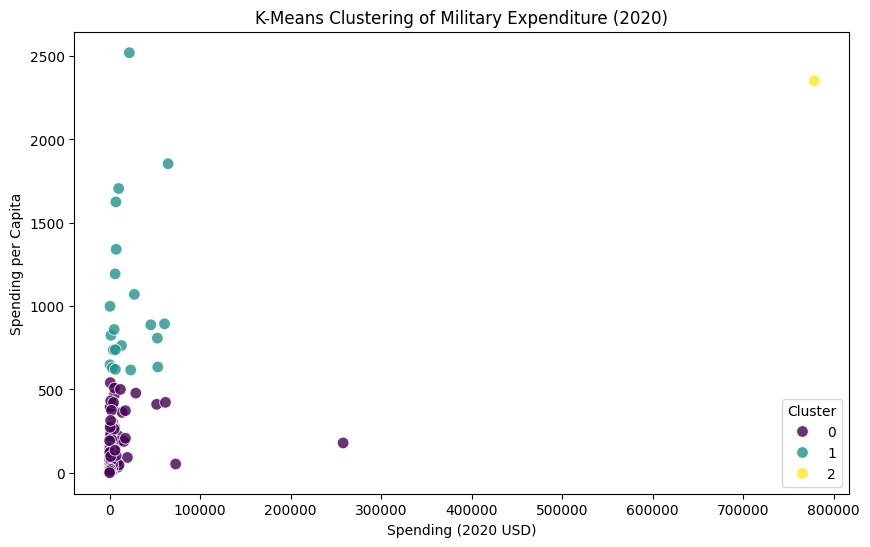

Cluster                                0             1              2
Spending (2020 USD) count     126.000000     21.000000       1.000000
                    mean     5943.346303  19975.991473  778397.200000
                    std     24858.961064  21749.736747            NaN
                    min         8.622460    405.790494  778397.200000
                    25%       162.761743   4980.428135  778397.200000
                    50%       580.758315   7269.880030  778397.200000
                    75%      3225.333414  27300.894701  778397.200000
                    max    257973.429834  64558.400000  778397.200000
Spending per Capita count     126.000000     21.000000       1.000000
                    mean      122.034996   1046.433509    2351.631858
                    std       140.041183    501.631845            NaN
                    min         0.580129    616.854430    2351.631858
                    25%        18.505805    737.690186    2351.631858
                    

In [12]:
# fit model with chosen optimal k = 3
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
data2['Cluster'] = final_kmeans.fit_predict(data2[['Spending_Scaled', 'PerCapita_Scaled']])

# scatter plot of Spending (2020 USD) and Spending per Capita

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# making scatter plot with Seaborn
sns.scatterplot(
    data=data2,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='Cluster',
    palette='viridis',
    s=70,
    alpha=0.8
)

plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('K-Means Clustering of Military Expenditure (2020)')
plt.legend(title='Cluster')
plt.show()

# describe table

cluster_summary_transposed = data2.groupby('Cluster')[['Spending (2020 USD)', 'Spending per Capita']].describe().T
print(cluster_summary_transposed)

In [13]:
# finding which cluster is the US
print(data2[data2['Cluster'] == 2]['Country'].values)

['United States of America']


In [14]:
# looking at the above plots, we can see that it is very right skew.
# the majority of the countries are clustered at the bottom left.
# there is also a massive gap between the clusters and a point all the way to the far right.
# the the US is in cluster 2 on the far right (the yellow dot).
# cluster 0 likely represents the global baseline as it includes 126 countries and has a very low mean spending.
# cluster 1 likely represents more developed countries with higher spending of about 20 billion.
# lastly, cluster 2 represents the extreme outlier countries with the highest spending; in this case, the US is the only country in this cluster as it stands out with about $778 billion.

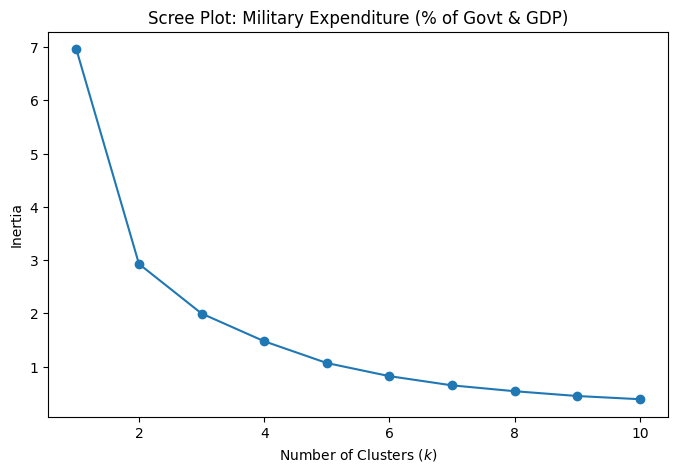

In [15]:
# 3

# similar to part 2 but replace features with Percent of Government Spending and Percent of GDP

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# max-min normalize new features
scaler = MinMaxScaler()
features = ['Percent of Government Spending', 'Percent of GDP']
data2[['GovSpending_Scaled', 'GDP_Scaled']] = scaler.fit_transform(data2[features])

# optimal number of clusters using scree plot
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data2[['GovSpending_Scaled', 'GDP_Scaled']])
    inertia.append(kmeans.inertia_)

# plot scree plot
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-')
plt.xlabel('Number of Clusters ($k$)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Military Expenditure (% of Govt & GDP)')
plt.show()


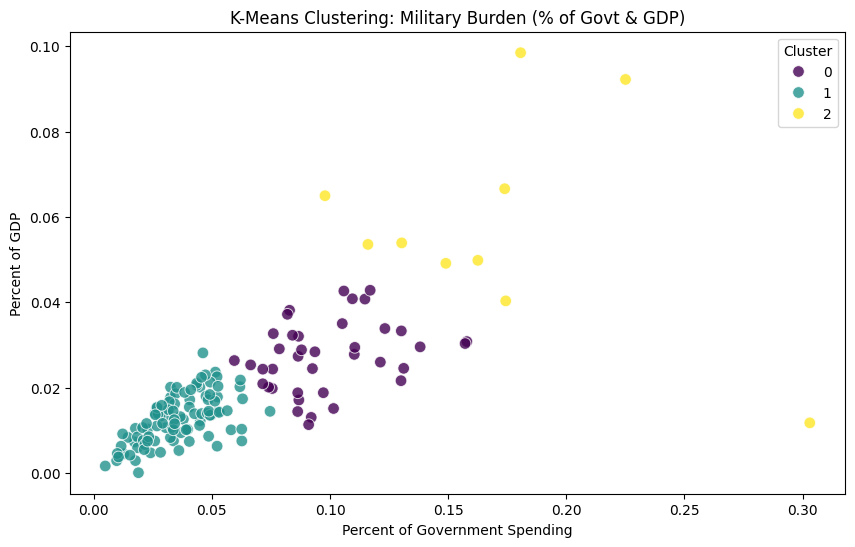

Cluster                                       0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    0.098683   0.035777   0.171289
                               std     0.024125   0.014549   0.058725
                               min     0.059520   0.004896   0.097882
                               25%     0.082430   0.025921   0.135010
                               50%     0.092044   0.034261   0.168248
                               75%     0.112633   0.047402   0.179081
                               max     0.157918   0.074624   0.303027
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    0.027412   0.012664   0.058071
                               std     0.008191   0.005681   0.024867
                               min     0.011317   0.000054   0.011742
                               25%     0.021254   0.008393   0.049297
                    

In [16]:
# fitting model with chosen k = 3
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
data2['Cluster'] = final_kmeans.fit_predict(data2[['GovSpending_Scaled', 'GDP_Scaled']])

# scatter plot with cluster hue
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data2,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='Cluster',
    palette='viridis',
    s=70,
    alpha=0.8
)
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.title('K-Means Clustering: Military Burden (% of Govt & GDP)')
plt.legend(title='Cluster')
plt.show()

# describe table
cluster_summary_transposed = data2.groupby('Cluster')[['Percent of Government Spending', 'Percent of GDP']].describe().T
print(cluster_summary_transposed)

In [17]:
# results comparison to part 2:

# in comparison to part 2, there are now 10 countries in cluster 2 as opposed to only 1 previously.
# additionally, since the data is measured as ratios (unlike the part 2), the data is on a much tighter and normalized scale.
# also, the plot is much less severely skewed to the right than Part 2, but it still shows some upper skew.

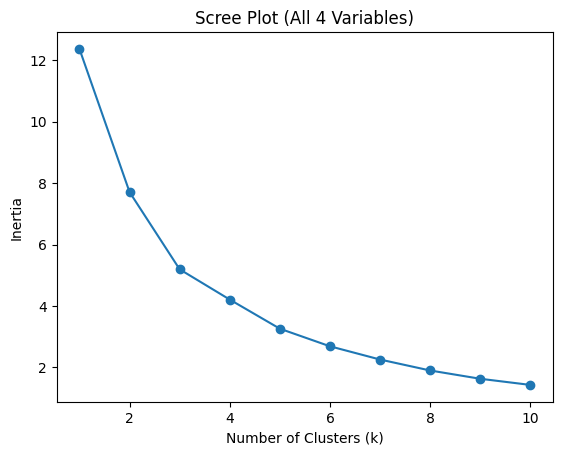

In [18]:
# 4

# K-means clustering with all 4 variables

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# select + normalize all 4 features
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
scaled_cols = ['S1', 'S2', 'S3', 'S4']
data2[scaled_cols] = MinMaxScaler().fit_transform(data2[features])

# scree plot
inertia = []
for k in range(1, 11):
    inertia.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(data2[scaled_cols]).inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot (All 4 Variables)')
plt.show()

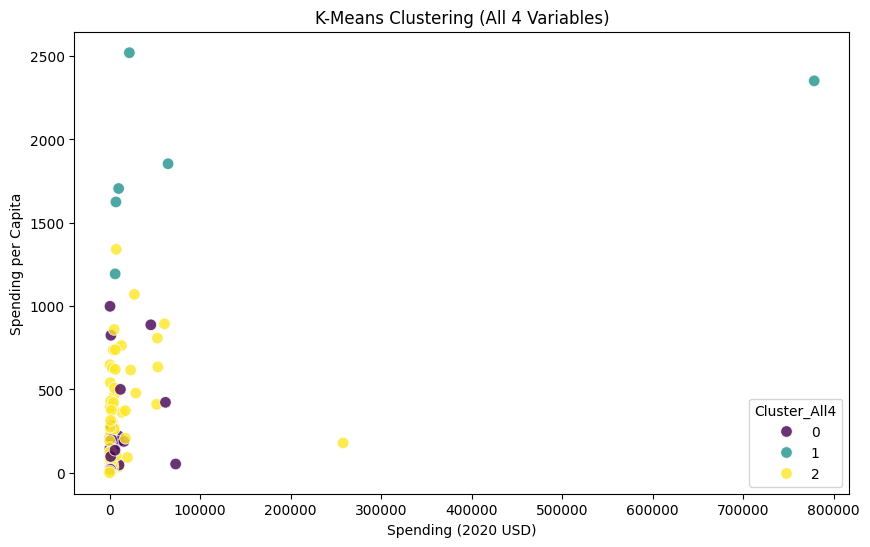

Cluster_All4                                     0              1  \
Spending (2020 USD)            count     31.000000       6.000000   
                               mean    8786.086602  147964.582042   
                               std    17901.909108  309635.189564   
                               min      162.373364    6095.708713   
                               25%      467.787851    7700.424616   
                               50%     1404.787234   15897.570598   
                               75%     7739.166193   53872.942442   
                               max    72937.064048  778397.200000   
Spending per Capita            count     31.000000       6.000000   
                               mean     212.689100    1875.150751   
                               std      257.841988     489.800206   
                               min       18.297119    1193.598730   
                               25%       46.485917    1645.301864   
                               50%

In [19]:
# fit model using optimal k = 3
optimal_k = 3
data2['Cluster_All4'] = KMeans(n_clusters=optimal_k, random_state=42, n_init=10).fit_predict(data2[scaled_cols])

# scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data2, x='Spending (2020 USD)', y='Spending per Capita', hue='Cluster_All4', palette='viridis', s=70, alpha=0.8)
plt.title('K-Means Clustering (All 4 Variables)')
plt.show()

# describe table
print(data2.groupby('Cluster_All4')[features].describe().T)

In [20]:
# results comparison to the previous two parts:

# the second cluster here is the baseline majority as it contains 111 countries.
# cluster 0 contains countries with moderate/high mean percentage of government spending and represents the mid-tier nations.
# lastly, cluster 1 is the highest tier, which is indicated by the descriptive table that highlights the maximum absolute spending of 778,397.
# in part 2, the US was completely isolated on the far right end; however, now there are 5 other countries that join it as they share similar data
# this part balances both scale and policy unlike part 2 (which was only focused on size) and part 3 (which only tracked budget priorities).

In [21]:
# 5

# the K-means clustering algorithm definitely helped find useful patterns to enhance spending analysis.
# specifically, it showed the limitations that came with the absolute scale (like looking at only dollars in part 2).
# part 3 also allowed us to see which countries truly prioritized military priority by using relative percentages
# lastly, combining all 4 variables allowed us to see through a more combinatorial lens, where we can see the contrast between scale and priority variables.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]